# Задача 4.2 — Перестановки мужчин и женщин

---

## 1. Условие

5 мужчин и 5 женщин случайным образом рассаживаются в ряд на 10 мест. Найдите вероятности событий:

- $A$ — любые две женщины не сидят рядом;
- $B$ — все мужчины сидят рядом.

**Ответ:** $P(A) = P(B) = \dfrac{1}{42}$.

---

## 2. Теоретическая часть

Общее число рассадок — $10!$ (все люди различимы).

### Событие A — женщины не рядом

Сначала расставляем 5 мужчин: $5!$ способов. Между ними и по краям образуется 6 «щелей»; выбираем 5 из них для женщин: $\binom{6}{5}$, и расставляем женщин: $5!$. Итого

$$
P(A) = \frac{5! \cdot \binom{6}{5} \cdot 5!}{10!}.
$$

### Событие B — все мужчины рядом

Считаем блок из 5 мужчин как один объект: $5!$ способов переставить мужчин внутри блока, $(5+1)! = 6!$ способов расставить блок и 5 женщин. Итого

$$
P(B) = \frac{5! \cdot 6!}{10!}.
$$

---

## 3. Решение

P(A) = 0.023809523809523808 = 1/42
P(B) = 0.023809523809523808 = 1/42


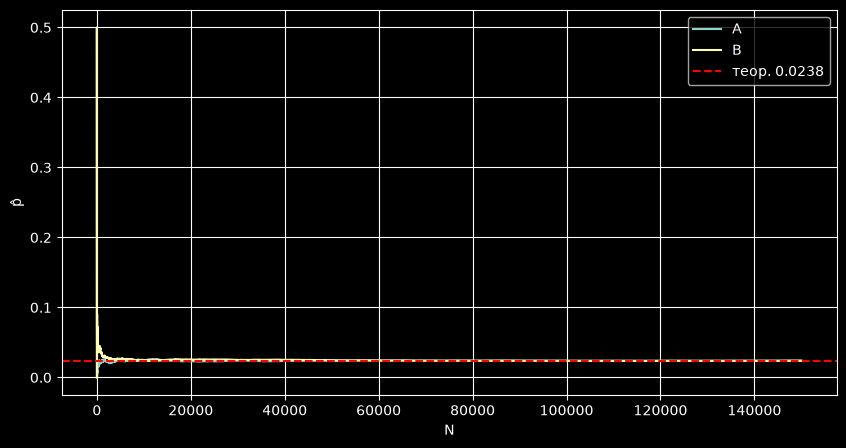

In [1]:
from math import factorial, comb
import numpy as np
import matplotlib.pyplot as plt

P_A = factorial(5) * comb(6, 5) * factorial(5) / factorial(10)
P_B = factorial(5) * factorial(6) / factorial(10)
print(f"P(A) = {P_A} = 1/{round(1/P_A)}")
print(f"P(B) = {P_B} = 1/{round(1/P_B)}")

# ---------- Моделирование ----------
def simulate(N, seed=0):
    rng = np.random.default_rng(seed)
    hits_A = np.zeros(N, dtype=bool)
    hits_B = np.zeros(N, dtype=bool)
    for i in range(N):
        arr = rng.permutation(10)          # 0..4 — мужчины, 5..9 — женщины
        is_woman = arr >= 5
        # A: никакие две женщины не рядом
        hits_A[i] = not np.any(is_woman[:-1] & is_woman[1:])
        # B: все мужчины рядом => все женщины занимают 5 подряд идущих мест
        idx = np.where(is_woman)[0]
        hits_B[i] = (idx.max() - idx.min() == 4)
    return hits_A, hits_B

N = 150_000
hA, hB = simulate(N, seed=1)
fA = np.cumsum(hA) / np.arange(1, N+1)
fB = np.cumsum(hB) / np.arange(1, N+1)

plt.figure(figsize=(10, 5))
plt.plot(fA, label="A")
plt.plot(fB, label="B")
plt.axhline(P_A, color="r", ls="--", label=f"теор. {P_A:.4f}")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.show()